<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/hough_cember.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

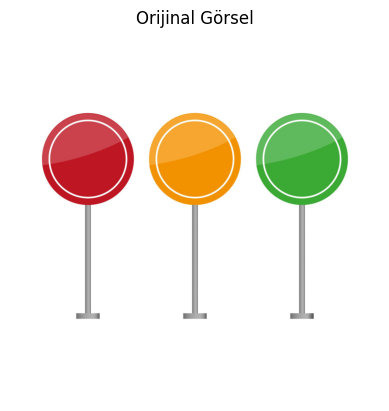

In [3]:
resim = cv2.imread("image10.jpeg")
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Görsel")
plt.axis("off")
plt.show()

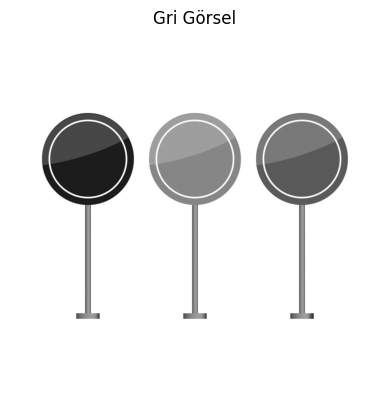

In [4]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

plt.imshow(gri, cmap="gray")
plt.title("Gri Görsel")
plt.axis("off")
plt.show()

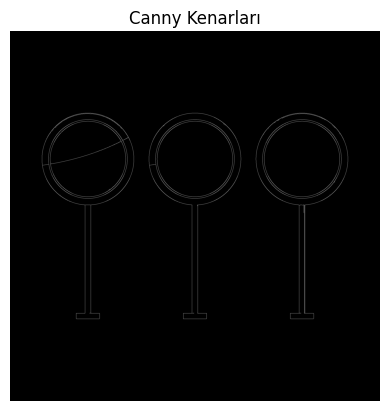

In [5]:
kenarlar = cv2.Canny(gri, 50, 150)

plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")
plt.show()

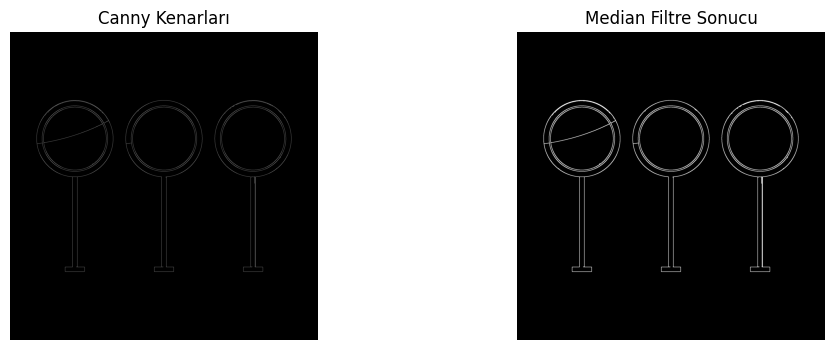

In [9]:
kernel = np.ones((3, 3), np.uint8)

kalin = cv2.dilate(kenarlar, kernel, iterations=1)

median = cv2.medianBlur(kalin, 3)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(median, cmap="gray")
plt.title("Median Filtre Sonucu")
plt.axis("off")

plt.show()

In [12]:
h, w = median.shape

cemberler = cv2.HoughCircles(
    median,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=int(w * 0.22),
    param1=120,
    param2=50,
    minRadius=int(w * 0.07),
    maxRadius=int(w * 0.15)
)

if cemberler is not None:
    cemberler = np.round(cemberler[0]).astype(int)
    print("Bulunan çember sayısı:", len(cemberler))
else:
    print("Çember bulunamadı.")

Bulunan çember sayısı: 3


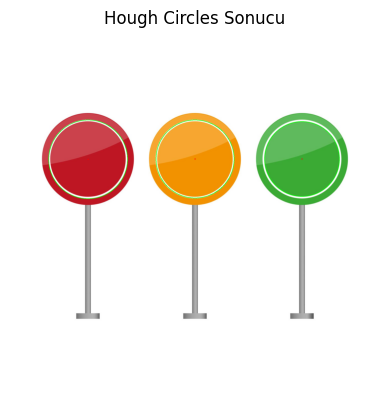

In [13]:
sonuc = resim.copy()

if cemberler is not None:
    for x, y, r in cemberler:

        # Çemberi yeşil çiz
        cv2.circle(sonuc, (x, y), r, (0, 255, 0), 2)

        # Merkezi kırmızı noktayla göster
        cv2.circle(sonuc, (x, y), 3, (0, 0, 255), -1)

plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Hough Circles Sonucu")
plt.axis("off")
plt.show()